# Song et al. 2022 — Prostate Cancer · 01 Preprocessing
Malignant-cell manifold for the CCCA embryonic-program analysis. Seq-Well S3, 15 samples.
Load malignant cells → drop under-populated samples → overdispersed genes → PCA → Harmony(`sample`) → UMAP → island removal → Leiden lobes → subtype annotation → **Gate 1**.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Song2022_Prostate | category: Prostate


### Load malignant cells
The loader auto-detects normalization from the matrix filename (`Exp_data_UMIcounts.mtx` → counts → `normalize_total` + `log1p`) and sets `celltype`.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(), '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Song2022_Prostate
Done.
full atlas: (21743, 21877)
malignant: (4658, 21877) | samples: 15 | patients: 11
expression: X max 6.16 (log1p of normalize_total UMI counts)


### Sample threshold — multiplicative-gap finder
Sort per-sample malignant counts; the largest multiplicative gap sets the cut. When the gap sits at the top of the distribution (degenerate — a smooth tail with no clean break), fall back to a >=100-cell floor.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100
if gap == 0:
    print(f'gap is at the top of the distribution (degenerate) -> fall back to >= {FLOOR}-cell floor')
    thresh = FLOOR
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample kept = {int(n[keep].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [1137  633  588  466  311  268  235  174  150  135  130  130  110  107
   84]
largest multiplicative gap: 1137 -> 633 (ratio 1.80) at rank 0
gap is at the top of the distribution (degenerate) -> fall back to >= 100-cell floor
kept 14/15 samples (min per-sample kept = 107) -> 4574 cells


### Overdispersed genes → PCA → Harmony integration on `sample`
Theta swept 2/5/10 against a per-cell same-sample neighbour fraction; take the strongest integration before the mixing metric plateaus.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 199 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 199
2026-07-31 21:13:04,410 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-31 21:13:06,251 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-31 21:13:06,284 - harmonypy - INFO - Iteration 1 of 30
2026-07-31 21:13:07,849 - harmonypy - INFO - Iteration 2 of 30
2026-07-31 21:13:09,405 - harmonypy - INFO - Iteration 3 of 30
2026-07-31 21:13:10,451 - harmonypy - INFO - Iteration 4 of 30
2026-07-31 21:13:11,272 - harmonypy - INFO - Iteration 5 of 30
2026-07-31 21:13:11,948 - harmonypy - INFO - Iteration 6 of 30
2026-07-31 21:13:13,107 - harmonypy - INFO - Iteration 7 of 30

### Island removal — UMAP radius graph, keep the largest connected component

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
after island removal: 4574 cells


### Leiden lobes + subtype annotation
Prostate malignant cells are near-uniformly luminal/AR-driven (KLK3 in ~97% of cells; basal KRT5/TP63, club SCGB1A1, and neuroendocrine CHGA/SYP markers all near zero). Two density lobes (Leiden res=0.15) are labelled by AR-target output and Wilcoxon markers: an **AR-active** lobe (KLK3/KLK2/ACPP-high) and an **AR-low** ribosomal-protein-dominant lobe. Both are ERG-mixed (Song 2022 reports intermixed ERGpos/ERGneg luminal tumour states).

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
# Prostate subtype signatures (canonical luminal/basal/club/NE)
panels = {
 'luminal_AR': ['KLK3','KLK2','NKX3-1','AR','FOLH1','ACPP','TMPRSS2','MSMB','FKBP5','STEAP2'],
 'basal'     : ['KRT5','KRT14','TP63','KRT15'],
 'club'      : ['SCGB1A1','SCGB3A1','MMP7','LTF','PIGR'],
 'NE'        : ['CHGA','CHGB','SYP','ENO2'],
}
for nm,gs in panels.items():
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())
# label: higher AR-target output = Luminal-AR-active; other = Luminal-AR-low
ar = adata.obs.groupby('lobe', observed=True)['luminal_AR_score'].mean()
active_lobe = ar.idxmax()
lab_map = {l: ('Luminal-AR-active' if l==active_lobe else 'Luminal-AR-low')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 3916, '1': 658}
overall cycling fraction: 0.007
cycling fraction per lobe: {'0': 0.007, '1': 0.005}
luminal_AR: 10/10 genes | per-lobe mean {'0': 0.797, '1': 0.538}
basal: 4/4 genes | per-lobe mean {'0': -0.002, '1': 0.01}
club: 5/5 genes | per-lobe mean {'0': 0.003, '1': -0.015}
NE: 4/4 genes | per-lobe mean {'0': 0.001, '1': 0.003}
compartments: {'Luminal-AR-active': 3916, 'Luminal-AR-low': 658}


### House orientation (`X_umap_lin`)
Rigid rotation of the UMAP onto its variance axis, signed so the developmental-origin pole (pSom-high / Crest-low) sits on the left. Stored as `X_umap_lin` and re-used by every downstream panel so all UMAPs share one orientation (distances preserved; not a re-embedding).

In [8]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]     # pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'somitogenesis-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.01
house orientation: rigid rotation -46.0deg (distances preserved), somitogenesis-high origin pole on left; stored as X_umap_lin


### Gate 1 — mixing + continuity
iLISI (effective number of samples per neighbourhood) pre/post-Harmony, plus the single-component manifold after island removal. **Judged on the embedding**, not a scalar alone.

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.95 -> post-Harmony(theta=10) 7.12 of 14 samples
14 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


In [10]:
# coerce object columns to numeric where clean, else str (h5ad-safe)
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (4574, 17235)


### `samples.pdf` — sample-coloured manifold (Gate-1 evidence)
House `(3.5,1.5)` strip on the house orientation; per-neighbourhood sample intermixing across the strip is the batch-integration evidence.

saved samples.pdf | cells: 4574


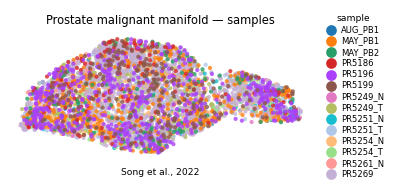

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Prostate malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Song et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])